# 03 · Real data

There is no truth here, so the questions change form:

* (A) *descriptive* — what pattern does the fit report?
* (B) *stability* — does it report the same pattern from different seeds? (replaces "recovery")
* (C) *identification* — does rotating a shared factor into a private one cost ELBO, and does that cost
  grow with $N$? (Q5 on a subsample vs the full data)

Datasets: **COVID** (metabolomic + proteomic, $M=2$) and the **four-view cohort table** (DNA, RNA, IF
densities, IF interactions, $M=4$). Caveats from notebook 00 apply (DNA is binary, fitted as Gaussian).

In [1]:
import os, sys, warnings
os.environ["TQDM_DISABLE"] = "1"
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks_sharedness" else os.getcwd()
sys.path.insert(0, ROOT)
os.chdir(ROOT)

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Markdown, display
from sharedness import experiments as ex, metrics as mt
from sharedness.data import make_view_data, H_EASY, pattern_for

pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid", context="notebook")
RESULTS = os.path.join(ROOT, "notebooks_sharedness", "results")
os.makedirs(RESULTS, exist_ok=True)

def outcome(code_text, title="Observed outcome"):
    code, text = code_text
    display(Markdown(f"> **{title}: {code}** — {text}"))
    return code

from sharedness.data import load_covid_views, load_four_view_cohort
from sharedness import realdata as rd
DATA = {"COVID (M=2)": load_covid_views(top=150, cohort_mode="grouped"),
        "four-view (M=4)": load_four_view_cohort(top=100)}
K_REAL = {"COVID (M=2)": 5, "four-view (M=4)": 6}
SEEDS = range(3)

## Q1 — Can CohortFACTM learn how often cohorts differ?

**Why we ask.** The cohort switch rate $\pi$ is fixed at 0.5 in CohortFACTM. If it can be learned, the model
reports how many cohorts actually have their own mean; if the learned value is biased, we need to know why
before trusting any cohort read-out.

**Setup.**

- **Data.** The real cohorts of each dataset (COVID severity groups; the 6 cancer types of the four-view table).
- **No truth.** There is no $\pi^\ast$. We therefore ask only whether the learned $\mathbb E[\pi]$ lands clearly
  inside $(0,1)$ with some switches off (as in the synthetic O1 case) or saturates near 1 (as in O2).
- **Repeats.** 3 seeds.

**What we fit.** Three cohort priors, all with ARD loadings:
1. **$\pi=0.5$ fixed** — CohortFACTM as it is today.
2. **$\pi$ learned, current factorisation** $q(\gamma)q(\delta)$ — $q(\pi)=\mathrm{Beta}(1+\sum_{c,k}\mathbb E\gamma_{ck},\,1+CK-\sum\mathbb E\gamma_{ck})$.
3. **$\pi$ learned, paired factorisation** $q(\gamma)q(\delta\mid\gamma)$ — the fix proposed in the model document.

**What we measure.**

- **$\mathbb E[\pi\mid Y]$** vs the true rate (effective rate on synthetic data). Good = close to the diagonal.
- **$\gamma$ AUC** $=P(\mathbb E\gamma_{ck}>\mathbb E\gamma_{c'k'}\mid G^{\text{eff}}_{ck}=1,\,G^{\text{eff}}_{c'k'}=0)$: does
  $\mathbb E\gamma$ rank the real shifts above the non-shifts? $1$ perfect, $0.5$ chance.
- **null $\mathbb E\gamma$** = mean $\mathbb E\gamma$ where the truth is 0 (should be low); **alt** = where it is 1.

**How to read the answer** (the rule the code applies, fixed before the run):

| Outcome | If we see | It would mean | So we |
|---|---|---|---|
| **O1** Learnable | max $|\mathbb E\pi-\pi^\ast|<0.15$ and $\mathbb E\pi$ rises with $\pi^\ast$ (slope $>0.5$) | the data carry the rate | keep $\pi$ learnable |
| **O2** Drifts to 1 | $\mathbb E\pi>0.8$ whatever $\pi^\ast$ is | switches that should be off are not pushed off | the factorisation, not the formula, is at fault — try the paired one |
| **O3** Prior-dominated | $\mathbb E\pi$ moves $<0.2$ across all $\pi^\ast$ | too few switches ($CK$) to learn from | leave $\pi$ fixed |
| **O4** Partial | anything else (moves with the truth but biased) | the rate is partly recoverable | report the bias and prefer the arm with the smallest one |

*Thresholds live in `sharedness/experiments.py`; the full statement is in notebook 00.*

On real data we cannot score $\mathbb E[\pi]$ against a truth. We ask instead: does the learned $\pi$
behave like the synthetic O1 case (a rate clearly inside $(0,1)$, with some switches clearly off) or like
O2 (everything on)?

In [2]:
q1r = rd.run_q1_real(DATA, K_REAL, seeds=SEEDS)
q1r.to_csv(os.path.join(RESULTS, "real_q1.csv"), index=False)
q1r.groupby(["dataset", "arm"])[["E_pi", "sd_pi", "frac_gamma_on", "frac_gamma_off"]].mean()

E_pi  sd_pi  frac_gamma_on  \
dataset         arm                                                   
COVID (M=2)     fixed pi=0.5 (current)  0.500  0.000          0.600   
                learned pi (current q)  0.904  0.068          0.956   
                learned pi (paired q)   0.663  0.107          0.556   
four-view (M=4) fixed pi=0.5 (current)  0.500  0.000          0.602   
                learned pi (current q)  0.970  0.027          1.000   
                learned pi (paired q)   0.822  0.059          0.759   

                                        frac_gamma_off  
dataset         arm                                     
COVID (M=2)     fixed pi=0.5 (current)           0.356  
                learned pi (current q)           0.022  
                learned pi (paired q)            0.156  
four-view (M=4) fixed pi=0.5 (current)           0.352  
                learned pi (current q)           0.000  
                learned pi (paired q)            0.019

In [3]:
for name in DATA:
    outcome(rd.decide_q1_real(q1r, name), title=f"Observed outcome [{name}]")

> **Observed outcome [COVID (M=2)]: current q: drifts to 1; paired q: stays inside (0,1)** — current q: E[pi] = 0.90 ± 0.07, 2% of switches off; paired q: E[pi] = 0.66 ± 0.11, 16% of switches off.

> **Observed outcome [four-view (M=4)]: current q: drifts to 1; paired q: drifts to 1** — current q: E[pi] = 0.97 ± 0.03, 0% of switches off; paired q: E[pi] = 0.82 ± 0.06, 2% of switches off.

## Q2 — Does a plain fit already show which factors are shared?

**Why we ask.** If an ordinary fit already reveals the shared/private pattern, no new model is needed to *see* it —
only (later) to *identify* it. This tells us whether the hard part is reading the pattern or finding the factors.

**What we fit.** Two loadings priors: **no prior** ($w\sim\mathcal N(0,1)$) and **ARD**. No cohort structure.

**What we measure.**

- **Variance share** $r_{mk}=\lVert\mathbb E z_{\cdot k}\,\mathbb E w^{(m)\top}_{\cdot k}\rVert_F^2/\lVert Y^{(m)}\rVert_F^2$:
  the fraction of view $m$'s variance carried by factor $k$. Normalise per factor to activity $a_{mk}\in[0,1]$.
- **Pattern AUC** $=P(a_{mk}>a_{m'k'}\mid H_{mk}=1,\,H_{m'k'}=0)$, after matching fitted to true factors
  (Hungarian on $|\mathrm{corr}|$). Threshold-free; $1$ perfect, $0.5$ chance. We report it with and without ARD.

**How to read the answer** (the rule the code applies, fixed before the run):

| Outcome | If we see | It would mean | So we |
|---|---|---|---|
| **O1** Yes, any fit | AUC $\ge0.95$ with and without ARD | sharedness is a read-out of the fit | no new model needed to see the pattern |
| **O2** Yes, with ARD | AUC $\ge0.95$ only with ARD | ARD is what makes the pattern readable | use ARD loadings when reading sharedness |
| **O3** Partly | best AUC in $[0.75,0.95)$ | some cells are read wrongly | inspect leaks (private read as shared) vs misses |
| **O4** No | best AUC $<0.75$ | the fit does not expose the pattern | the bottleneck is elsewhere (see Q2b) |

*Thresholds live in `sharedness/experiments.py`; the full statement is in notebook 00.*

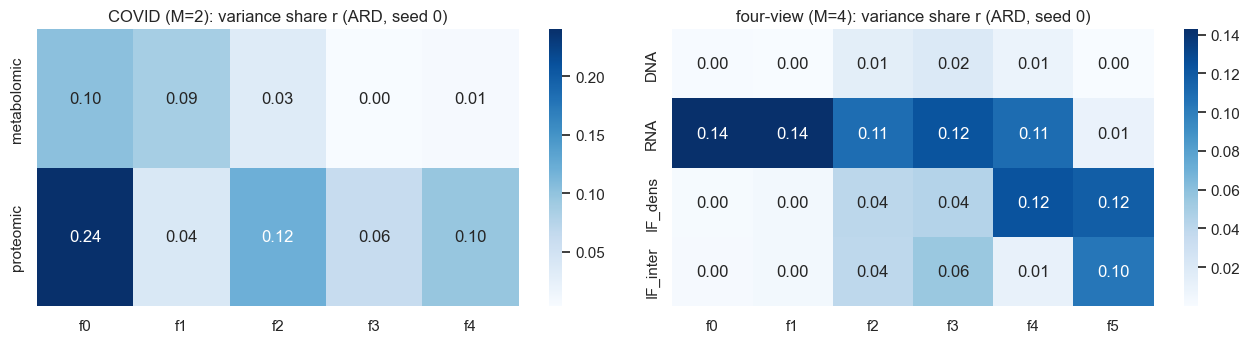

,stability_auc,S_k,matched_corr
COVID (M=2),0.724,"[0.88, 0.89, 0.76, 0.31, 0.34]","[0.91, 0.79, 0.57, 0.72, 0.69]"
four-view (M=4),0.898,"[0.12, 0.19, 0.84, 0.87, 0.69, 0.6]","[0.78, 0.79, 0.76, 0.58, 0.95, 0.84]"


In [4]:
q2r = rd.run_q2_real(DATA, K_REAL, seeds=SEEDS)
fig, axes = plt.subplots(1, len(DATA), figsize=(13, 3.6))
for ax, name in zip(axes, DATA):
    r = q2r[name]["r_ref"]
    sns.heatmap(r, ax=ax, cmap="Blues", annot=True, fmt=".2f",
                yticklabels=DATA[name].view_names, xticklabels=[f"f{k}" for k in range(r.shape[1])])
    ax.set_title(f"{name}: variance share r (ARD, seed 0)")
plt.tight_layout(); plt.show()
pd.DataFrame({name: dict(stability_auc=q2r[name]["stability"], S_k=np.round(q2r[name]["S_ref"], 2).tolist(),
                         matched_corr=np.round(q2r[name]["match_corr"], 2).tolist()) for name in DATA}).T

In [5]:
for name in DATA:
    outcome(rd.decide_q2_real(q2r[name]), title=f"Observed outcome [{name}]")

> **Observed outcome [COVID (M=2)]: partly stable** — activity matrices agree across seeds with corr 0.72; the least stable factor matches at |corr| 0.57.

> **Observed outcome [four-view (M=4)]: partly stable** — activity matrices agree across seeds with corr 0.90; the least stable factor matches at |corr| 0.58.

## Q3 — How many views are needed before shared-vs-private is a meaningful question?

**Why we ask.** With 2 views there are only 3 possible patterns; with 4 there are 15. We need to know whether few
views make the pattern merely *coarse* or actually *hard to detect* — this decides whether COVID ($M=2$) is a
usable test bed.

**Setup.** No fitting: the datasets are fixed. We only note the pattern count ($2^M-1$ = 3 for COVID, 15 for
the four-view table) and recall the synthetic answer for whether $M=2$ suffices to detect a pattern.

**What we fit.** ARD loadings, no cohort structure, one fit per $(M,\text{seed})$.

**What we measure.** **AUC of ARD activity against $H$** (as in Q2), averaged over seeds, for each $M$. Good = high and
flat across $M$; a rise with $M$ means more views help detection.

**How to read the answer** (the rule the code applies, fixed before the run):

| Outcome | If we see | It would mean | So we |
|---|---|---|---|
| **O1** M does not limit detection | AUC $\ge0.95$ at every $M$ | even $M=2$ detects the pattern, just coarsely | COVID is usable; more views only add resolution |
| **O2** More views help | AUC rises by $\ge0.05$ from the smallest to the largest $M$ | detection improves with views | prefer the four-view data over COVID |
| **O3** More views hurt | AUC falls by $\ge0.05$ | more private factors split the signal | cap the number of views / factors |
| **O4** Flat but imperfect | otherwise | detection is limited by something other than $M$ | look at noise / factor strength instead |

*Thresholds live in `sharedness/experiments.py`; the full statement is in notebook 00.*

Q3 on real data is the inventory itself: COVID has $2^2-1=3$ possible patterns, the four-view table $15$.
The synthetic answer (notebooks 01–02) says whether $M=2$ is enough to *detect* the pattern; here we only
note that every COVID factor must be one of {shared, metabolomic-only, proteomic-only}.

## Q4 — Does an explicit on/off view switch beat ARD's soft dials?

**Why we ask.** ARD turns a factor's loadings in a view *down* but never fully *off*, so any yes/no call needs an
arbitrary cutoff. A real switch $h_{mk}$ would give a direct answer — if it is identifiable.

**Setup.** Each dataset, 3 seeds. No truth: we report how many switches stay on and whether seeds agree,
and we compare the ARD slab against a fixed slab.

**What we fit.** Four arms: **ARD** (reference, no switch); **switch, cold start**; **switch, warm start** (started from a
converged ARD fit); **switch, warm start + fixed slab** (slab precision $\alpha\equiv1$ instead of learned ARD).

**What we measure.**

- **Switch AUC** of $\mathbb E[h]$ against $H$ (as in Q2).
- **Decisiveness** = share of $\mathbb E[h_{mk}]$ outside $(0.1,0.9)$ — are the calls confident?
- **Switches on** = share with $\mathbb E[h]>0.5$ (true value 50% in the synthetic pattern).
- **Leaks** (private called shared) and **misses** (shared called absent).

**How to read the answer** (the rule the code applies, fixed before the run):

| Outcome | If we see | It would mean | So we |
|---|---|---|---|
| **O1** Cleaner | best switch AUC $\ge$ ARD$-0.02$, $\ge0.9$, and $\ge90\%$ decisive | the switch gives sharper correct calls | worth adding as a diagnostic |
| **O2** Switch stays on | $\ge95\%$ of switches on in the best arm | $h$ cannot tell itself apart from a shrunk slab ($\alpha\to\infty$ and $h=0$ look the same) | drop the switch or use a fixed slab |
| **O3** Worse than ARD | best switch AUC $<$ ARD$-0.05$ | the switch harms recovery | keep ARD |
| **O4** Mixed | otherwise | it depends on the slab | report per arm |

*Thresholds live in `sharedness/experiments.py`; the full statement is in notebook 00.*

Two switches: with an **ARD slab** (as in the synthetic `switch_warm` arm) and with a **fixed slab**
($\alpha\equiv 1/0.25$; loadings of standardised views are small, so the synthetic value 1 would be too wide).

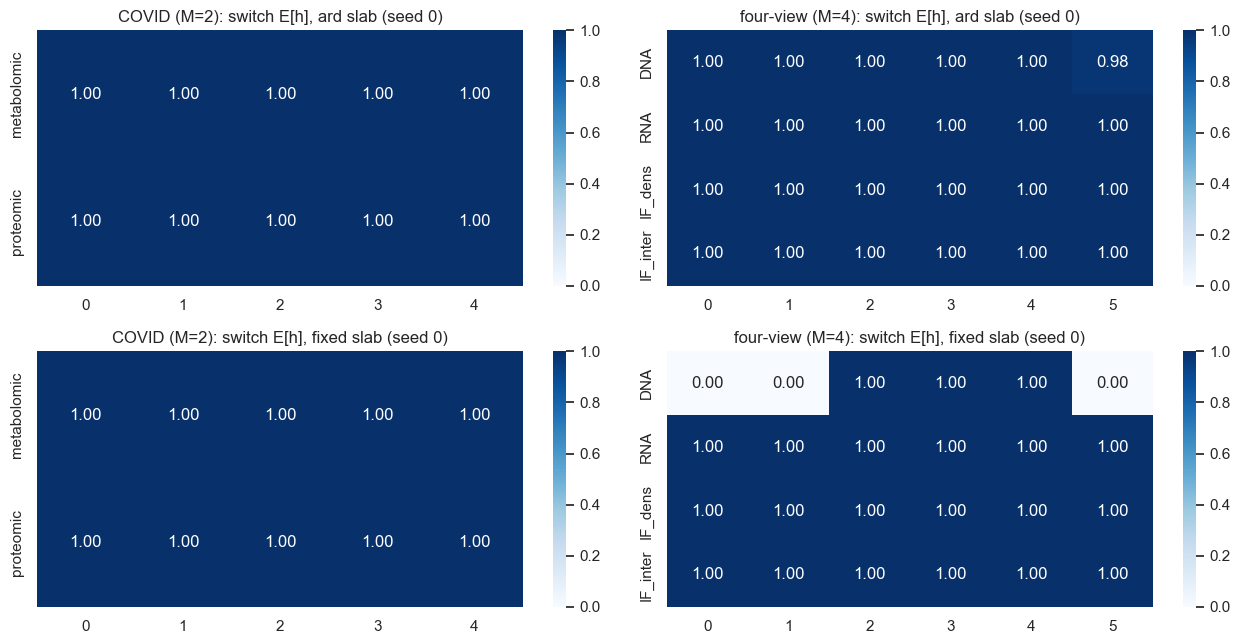

on_share decisive seed_agreement ard_vs_switch_auc  \
COVID (M=2)     ard        1.0      1.0            1.0               NaN   
                fixed      1.0      1.0           0.95               NaN   
four-view (M=4) ard        1.0      1.0            1.0               NaN   
                fixed    0.875      1.0          0.896               NaN   

                      monotone  
COVID (M=2)     ard       True  
                fixed     True  
four-view (M=4) ard       True  
                fixed     True

In [6]:
q4r = rd.run_q4_real(DATA, K_REAL, seeds=SEEDS)
fig, axes = plt.subplots(2, len(DATA), figsize=(13, 6.6))
for j, name in enumerate(DATA):
    for i, slab in enumerate(["ard", "fixed"]):
        sns.heatmap(q4r[name][slab]["E_h_ref"], ax=axes[i, j], cmap="Blues", annot=True, fmt=".2f",
                    vmin=0, vmax=1, yticklabels=DATA[name].view_names)
        axes[i, j].set_title(f"{name}: switch E[h], {slab} slab (seed 0)")
plt.tight_layout(); plt.show()
pd.DataFrame({(n, sl): {k: v for k, v in q4r[n][sl].items() if not isinstance(v, np.ndarray)}
              for n in DATA for sl in q4r[n]}).T

In [7]:
for name in DATA:
    for slab in q4r[name]:
        outcome(rd.decide_q4_real(q4r[name][slab]), title=f"Observed outcome [{name} · {slab} slab]")

> **Observed outcome [COVID (M=2) · ard slab]: switch stays on (like O2)** — 100% of switches on, 100% decisive, seed agreement 100%, ARD agrees with the switch at AUC nan.

> **Observed outcome [COVID (M=2) · fixed slab]: switch stays on (like O2)** — 100% of switches on, 100% decisive, seed agreement 95%, ARD agrees with the switch at AUC nan.

> **Observed outcome [four-view (M=4) · ard slab]: switch stays on (like O2)** — 100% of switches on, 100% decisive, seed agreement 100%, ARD agrees with the switch at AUC nan.

> **Observed outcome [four-view (M=4) · fixed slab]: mixed** — 88% of switches on, 100% decisive, seed agreement 90%, ARD agrees with the switch at AUC nan.

## Q5 — Do forced zeros pin the factors down better than learned zeros?

**Why we ask.** This is the headline. A *frozen* zero (‘factor 2 never appears in view 1’) should make a
shared↔private rotation impossible; a *learned* zero can be switched back on. If the frozen penalty grows with
$N$ and the learned one does not, only a prescribed pattern identifies the split.

**Setup.** Same idea, but the reference factors are the ARD fit's own (no truth): rotate its most shared
factor into its most private one. The frozen arm fixes the pattern read off that fit. "Grows with $N$" is checked
on a random quarter of the samples vs all of them.

**What we fit.** Three arms, each re-optimised at every angle: **ARD** (no view structure); **learned switch**;
**frozen pattern** (the true $H$ on synthetic data; the read-off pattern on real data).

**What we measure.** **$\Delta(\theta)=\mathrm{ELBO}(0)-\mathrm{ELBO}(\theta)$** (nats): how hard the model resists the rotation.
We read its **growth from $N$ to $4N$**: a ratio near $4$ means the penalty scales with $N$ (likelihood-level
identification); a ratio near $1$ means a fixed, prior-level preference.

**How to read the answer** (the rule the code applies, fixed before the run):

| Outcome | If we see | It would mean | So we |
|---|---|---|---|
| **O1** Flat | $\Delta<5$ nats at the larger $N$ | rotating shared into private is essentially free | no identification from this mechanism |
| **O2** Grows like N | gap ratio $\ge0.6\times$ the sample-size ratio | the split is pinned at the likelihood level | a prescribed pattern identifies it (the `lem:zeros` regime) |
| **O3** Grows slower than N | otherwise | there is a real penalty but it does not scale with $N$ | a preference, not identification |

*Thresholds live in `sharedness/experiments.py`; the full statement is in notebook 00.*

Real-data version: the reference is the seed-0 ARD fit of Q2. Rotate its most shared factor (largest
$S_k$) into its most private one (smallest $S_k$). The **frozen** arm fixes the pattern
$\text{mask}_{mk}=\mathbb 1\{a_{mk}\ge 0.1\}$ read off that same fit's variance shares — a prescribed pattern
with real zeros (the learned ARD-slab switch produces none on these data, see Q4). "Grows with $N$" is checked
on a random quarter of the samples against all of them.

In [8]:
q5r = rd.run_q5_real(DATA, K_REAL, q2r)
q5r.to_csv(os.path.join(RESULTS, "real_q5.csv"), index=False)
for name, mask in rd.q5_real_masks(q2r).items():
    print(name, "prescribed pattern (views x factors):\n", mask)
q5r.groupby(["dataset", "arm", "N", "theta"])["gap"].mean().unstack("theta")

COVID (M=2) prescribed pattern (views x factors):
 [[1 1 1 0 0]
 [1 1 1 1 1]]
four-view (M=4) prescribed pattern (views x factors):
 [[0 0 1 1 0 0]
 [1 1 1 1 1 0]
 [0 0 1 1 1 1]
 [0 0 1 1 0 1]]


theta                                              0        15       30  \
dataset         arm                         N                             
COVID (M=2)     ARD (no switch)             94    0.0   -2.010   -2.779   
                                            378   0.0  115.738  232.178   
                frozen (prescribed pattern) 94    0.0   39.975   85.570   
                                            378   0.0  191.962  558.894   
                learned switch              94    0.0  -38.237  -38.523   
                                            378   0.0   52.546  168.987   
four-view (M=4) ARD (no switch)             260   0.0   31.279   75.315   
                                            1038  0.0   42.254  101.990   
                frozen (prescribed pattern) 260   0.0   46.096  230.399   
                                            1038  0.0  149.510  869.117   
                learned switch              260   0.0   46.096  230.399   
                                            1038  0.0  152.286  -68.605   

theta                                                   45  
dataset         arm                         N               
COVID (M=2)     ARD (no switch)             94      -5.711  
                                            378    261.111  
                frozen (prescribed pattern) 94     108.566  
                                            378   1166.920  
                learned switch              94     -41.588  
                                            378    197.919  
four-view (M=4) ARD (no switch)             260     89.399  
                                            1038   121.397  
                frozen (prescribed pattern) 260    497.829  
                                            1038  1914.030  
                learned switch              260     82.074  
                                            1038   -48.748

In [9]:
for name in DATA:
    for arm, oc in rd.decide_q5_real(q5r[q5r.dataset == name]).items():
        outcome(oc, title=f"Observed outcome [{name} · {arm}]")

> **Observed outcome [COVID (M=2) · ARD (no switch)]: O3** — GROWS, RATE UNDEFINED: gap -5.7 -> 261 nats; the small-N gap is ~0, so no growth rate can be read.

> **Observed outcome [COVID (M=2) · frozen (prescribed pattern)]: O2** — GROWS LIKE N: gap 109 -> 1167 nats (x10.7 for x4 samples).

> **Observed outcome [COVID (M=2) · learned switch]: O3** — GROWS, RATE UNDEFINED: gap -41.6 -> 198 nats; the small-N gap is ~0, so no growth rate can be read.

> **Observed outcome [four-view (M=4) · ARD (no switch)]: O3** — GROWS SLOWER THAN N: gap 89 -> 121 nats (x1.4 for x4 samples).

> **Observed outcome [four-view (M=4) · frozen (prescribed pattern)]: O2** — GROWS LIKE N: gap 498 -> 1914 nats (x3.8 for x4 samples).

> **Observed outcome [four-view (M=4) · learned switch]: O1** — FLAT: gap -48.7 nats at N=1038 (theta=45).

## Q6 — One sharing rate for the whole model, or one per factor?

**Why we ask.** A single $\pi$ answers ‘are this dataset's factors mostly shared?’; a per-factor $\pi_k$ answers ‘is
factor $k$ shared?’ — but $\pi_k$ is learned from only $M$ switches. We need to know if the finer version is worth
the extra uncertainty.

**Setup.** Each dataset, 3 seeds: compare the two modes' switch calls and the spread of $\pi_k$.

**What we fit.** View switch (fixed slab), global $q(\pi)=\mathrm{Beta}(1+\sum_{m,k}\mathbb E h_{mk},\,1+MK-\sum\mathbb E h_{mk})$
vs per-factor $q(\pi_k)=\mathrm{Beta}(1+\sum_m\mathbb E h_{mk},\,1+M-\sum_m\mathbb E h_{mk})$.

**What we measure.**

- **Switch AUC** in both modes (does per-factor recover the pattern any better?).
- **$\mathrm{sd}(\pi_k)$** — how uncertain the per-factor rate is (large when $M$ is small).
- **Separation** = mean $\mathbb E[\pi_k]$ over shared factors minus over private factors.

**How to read the answer** (the rule the code applies, fixed before the run):

| Outcome | If we see | It would mean | So we |
|---|---|---|---|
| **O1** Either works | $\mathrm{sd}(\pi_k)<0.15$ at $M\le4$ and no AUC gain | per-factor is certain enough and costs nothing | choose by interpretability |
| **O2** Use one global $\pi$ | $\mathrm{sd}(\pi_k)\ge0.15$ at $M\le4$ and no AUC gain | per-factor rates are noise at realistic $M$ | use a single $\pi$ |
| **O3** Per-factor helps | switch AUC gain $\ge0.03$ at some $M$ | the finer rate improves recovery there | keep $\pi_k$ where it helps |

*Thresholds live in `sharedness/experiments.py`; the full statement is in notebook 00.*

In [10]:
q6r = rd.run_q6_real(DATA, K_REAL, seeds=SEEDS)
q6r.to_csv(os.path.join(RESULTS, "real_q6.csv"), index=False)
q6r.groupby(["dataset", "mode"])[["on_share", "pi_mean", "pi_sd", "agreement_with_global"]].mean()

on_share  pi_mean  pi_sd  agreement_with_global
dataset         mode                                                       
COVID (M=2)     global         0.967    0.889  0.086                    1.0
                per_factor     0.967    0.733  0.196                    1.0
four-view (M=4) global         0.806    0.782  0.079                    1.0
                per_factor     0.806    0.704  0.162                    1.0

In [11]:
for name in DATA:
    outcome(rd.decide_q6_real(q6r, name), title=f"Observed outcome [{name}]")

> **Observed outcome [COVID (M=2)]: use one global pi (like O2)** — per-factor pi_k posterior sd 0.20; calls agree with global pi in 100% of cells.

> **Observed outcome [four-view (M=4)]: use one global pi (like O2)** — per-factor pi_k posterior sd 0.16; calls agree with global pi in 100% of cells.